In [35]:
import time
import sys
import re
from pathlib import Path
import numpy as np
import pandas as pd
import networkx as nx
import geopandas as gpd
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy.stats import rankdata
from pyproj import Transformer
from scipy.spatial import cKDTree
from sklearn.linear_model import Ridge
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedGroupKFold



In [2]:
# Lädt die gespeicherten Objekte aus Notebook 16, Notebook 16 zuerst ausführen

ORDNER = None      # hier den Pfad eintragen, falls die Suche nichts findet, z. B. r"C:\Users\...\daten_cache"

def finde_cache():
    hier = Path.cwd().resolve()
    kandidaten = [hier / "daten_cache", hier.parent / "daten_cache", *sorted(hier.parent.glob("*/daten_cache"))]
    for k in kandidaten:
        if (k / "paket.pkl").exists():
            return k

print("Arbeitsordner dieses Notebooks:", Path.cwd().resolve(), flush=True)
ORDNER = Path(ORDNER) if ORDNER else finde_cache()
if ORDNER is None or not (ORDNER / "paket.pkl").exists():
    raise SystemExit("paket.pkl nicht gefunden. Zelle 1 im alten Notebook ausführen und den Pfad aus der Zeile "
                     "'Gespeichert in ...' oben bei ORDNER eintragen.")
print("Lade aus:", ORDNER, flush=True)

paket = pd.read_pickle(ORDNER / "paket.pkl")
globals().update(paket)

for pfad in (ORDNER.parent, Path(".").resolve()):
    if str(pfad) not in sys.path:
        sys.path.insert(0, str(pfad))
try:
    from hilfsfunktionen import *            # norm_z, norm_adresse, ...
except Exception as ex:
    print("hilfsfunktionen.py konnte nicht geladen werden:", type(ex).__name__, ex)
if "norm_z" not in globals():
    norm_z = lambda s: "".join(ch for ch in str(s) if ch.isdigit()).lstrip("0")

print("Geladen:", ", ".join(paket))
print(f"Zähler mit Zeitreihe: {len(serien)} | Nodes im Graph: {G.number_of_nodes()} | Kanten: {G.number_of_edges()} | "
      f"Nodes mit Position: {len(pos)}")
fehlt = [n for n in ("serien", "knoten", "G", "pos", "roh", "linien", "kml_linien") if n not in globals()]
print("Für den Dashboard-Export fehlt:", fehlt or "nichts")

Arbeitsordner dieses Notebooks: C:\Users\pauli\Documents\Information Systems\2026 SoSe\Projektseminar\projektseminar-1\notebooks
Lade aus: C:\Users\pauli\Documents\Information Systems\2026 SoSe\Projektseminar\projektseminar-1\notebooks\daten_cache
Geladen: serien, knoten, G, G_orig, pos, roh, geschaetzt, linien, kml_linien, cache, koord_zaehler, ergebnis, e_nodes
Zähler mit Zeitreihe: 83 | Nodes im Graph: 111 | Kanten: 111 | Nodes mit Position: 111
Für den Dashboard-Export fehlt: nichts


In [3]:
# Die Quellensuche braucht das Skript, auch wenn das Dashboard selbst gar nicht geöffnet werden soll. Es berechnet unterwegs das Rohrnetz und die Zuordnung der Häuser.
%run -i dashboard_export.py

Hintergrund: 109 Gebäudelinien (Typ 6), 743 Rohrplan-Linien (Shapefile und KML)
Kanten auf Rohren: 106 von 111 | zu weit vom Rohrnetz: 0 | ohne Rohrverbindung: 5 (diese bleiben gerade Linien)
Geschrieben: C:\Users\pauli\Documents\Information Systems\2026 SoSe\Projektseminar\projektseminar-1\notebooks\fernwaerme_dashboard.html  (11.0 MB)
Zeitraum: 2024-01-01 00:00:00 bis 2025-05-31 23:00:00 (12408 Stunden)
Häuser mit Zeitreihe: 82 | Nodes: 111 | Kanten: 111
Graph ist ohne Kreise: True | Quellen: 8
WARNUNG: 9572 Werte lagen außerhalb des Speicherbereichs und wurden gekappt.
Startzeitpunkt im Dashboard: 2024-01-04 08:00:00
Datei im Browser öffnen (Doppelklick). Karte und Hintergrundkacheln brauchen Internet (Leaflet und Webkarte Bayern).
Hintergrund oben rechts in der Karte umschaltbar. OpenStreetMap geht nur, wenn die Datei über einen lokalen Server geöffnet wird:
  Terminal im Ordner der Datei:  python -m http.server 8000   dann im Browser  http://localhost:8000/fernwaerme_dashboard.htm

## Schätzung der Einspeisestelle aus dem Vorlauf

**Idee:** Der Vorlauf kühlt entlang der Leitung durch Wärmeverluste ab. Häuser nahe der Einspeisung
sehen im Mittel etwas wärmeres Vorlaufwasser als weit entfernte. Gesucht ist der Punkt im Rohrnetz,
zu dem diese Abstufung am besten passt.

**Voraussetzung:** Dashboard-Export (`%run -i dashboard_export.py`) ist gelaufen. Er liefert das
physische Rohrnetz `Gp` (Rohrplan aus Shapefile und KML, in ca. 2 m langen Stücken), die Zuordnung
der Häuser zum nächsten Rohrpunkt `snap` sowie `xy`, `nid`, `tr`.

**Schritte**
1. Pro Haus: Vorlauf nur aus Stunden mit Durchfluss > `MIN_FLUSS`, nur Heizsaison (`MONATE`).
   In jeder Stunde wird das Mittel aller Häuser abgezogen. Das entfernt Jahres- und Tageszeit.
   Pro Haus bleibt die mittlere Abweichung `delta` (in K).
2. Pro Haus: Rohrabstand zu jedem Punkt im Rohrnetz (kürzester Weg, Dijkstra).
3. Pro Kandidatenpunkt: Rangkorrelation (Spearman) zwischen `delta` und Abstand.
   An der echten Einspeisung fällt der Vorlauf mit dem Abstand, die Korrelation ist stark negativ.
4. Zufallsvergleich: 300-mal werden die Häuser vertauscht und die beste Korrelation neu bestimmt.
   Nur wenn der echte Wert deutlich besser ist als die 5%-Grenze, gibt es ein Signal.
5. Top-5-Kandidaten (mindestens 50 m auseinander) mit Koordinaten, nächstem Node und Gegenprobe:
   Wie viele Kanten der Edges-Datei zeigen vom Kandidaten weg (`kanten_stimmen`)?
   Die Kandidatenwahl nutzt die Kanten nicht, deshalb ist das eine unabhängige Prüfung.

**Lesehilfe**
- `korrelation` deutlich unter der Zufallsgrenze: Signal vorhanden.
- `K_pro_100m` muss negativ und klein sein.
- Hoher Anteil `kanten_stimmen`: Richtung der Edges-Datei und Temperaturgefälle passen zusammen.
- Die Karte zeigt, wie eindeutig die Lage ist. Auf unverzweigten Rohren sind viele Punkte gleich gut.

**Grenzen**
- Gefunden wird der Punkt, an dem die gemessenen Häuser "anfangen", nicht zwingend die Heizzentrale.
- Mehrere Einspeisepunkte lassen sich nicht trennen.
- Der Vorlaufunterschied ist klein. Stichleitungen mit wenig Durchfluss kühlen aus und verzerren.
- Ergebnis ist eine Schätzung und kein Messwert. Im Graphen als "Annahme" kennzeichnen.

Häuser: 82 | Stunden: 5461 | Spanne der Abweichung: -10.84 bis 6.61 K

Beste Korrelation: -0.70 | bei vertauschten Häusern erreicht man zufällig: -0.12 (Median), -0.26 (5%-Grenze)


,rang,korrelation,K_pro_100m,lat,lon,naechster_node,abstand_zum_node_m,kanten_stimmen,kanten_widersprechen
0,1,-0.70,-1.40,49.797846,10.347358,Nelkenstraße 2,28.0,59,51
1,2,-0.69,-1.25,49.797464,10.346964,Hans-Zander-Weg 1,18.0,58,52
2,3,-0.69,-1.22,49.796957,10.347166,Erzeuger (Annahme),39.0,58,52
3,4,-0.68,-1.22,49.798349,10.347473,Nelkenstraße 1,14.0,57,53
4,5,-0.67,-1.09,49.797244,10.346328,Hans-Zander-Weg 14,6.0,57,53


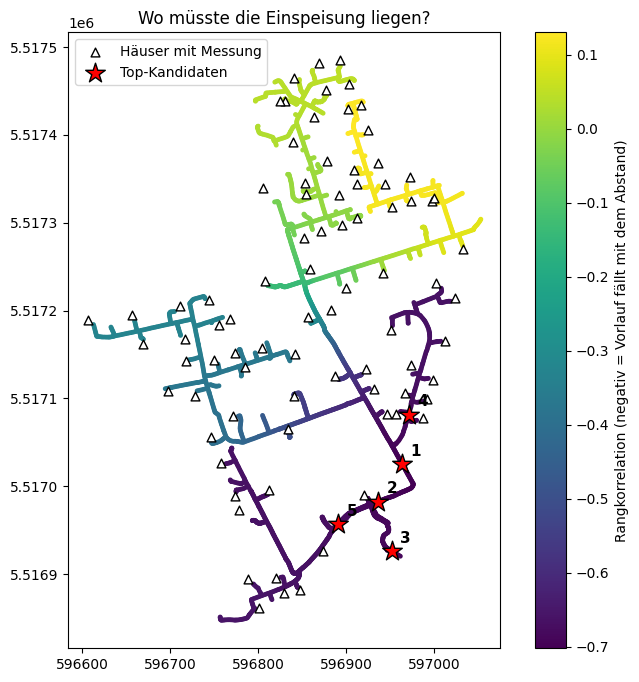

In [4]:


MIN_FLUSS = 40               # l/h: nur Stunden mit echtem Durchfluss
MONATE = [12, 1, 2]   # Heizsaison
MIN_HAEUSER_STUNDE = 20      # Stunden mit weniger Häusern werden nicht benutzt
MIN_STUNDEN = 200            # Häuser mit weniger Stunden werden nicht benutzt
ABSTAND_M = 50               # Kandidaten für die Top-Liste müssen so weit auseinander liegen

if "Gp" not in globals() or "snap" not in globals():
    raise SystemExit("Gp/snap fehlen: erst den Dashboard-Export (%run -i dashboard_export.py) laufen lassen.")
if not isinstance(xy, np.ndarray):
    raise SystemExit("`xy` wurde überschrieben (z. B. von der Graph-Zeichenzelle): Dashboard-Export erneut laufen lassen.")

nz = norm_z if "norm_z" in globals() else (lambda s: "".join(ch for ch in str(s) if ch.isdigit()).lstrip("0"))
zaehler_von = {r.edge_node: [nz(z) for z in str(r.zaehler).split(",") if nz(z)] for r in knoten.itertuples()}

# 1) Pro Haus: mittlere Abweichung des Vorlaufs vom Stundenmittel aller Häuser
spalten = {}
for r in knoten.itertuples():
    if r.edge_node not in nid:
        continue
    ds = [serien[z] for z in zaehler_von.get(r.edge_node, []) if z in serien]
    if ds:
        t = pd.concat([d["vor"].where(d["fluss"] > MIN_FLUSS) for d in ds], axis=1).mean(axis=1)
        spalten[r.edge_node] = t[t.index.month.isin(MONATE)]
T = pd.DataFrame(spalten)
T = T[T.notna().sum(axis=1) >= MIN_HAEUSER_STUNDE]
abw = T.sub(T.mean(axis=1), axis=0)
delta = abw.mean()[abw.notna().sum() >= MIN_STUNDEN]
haeuser = list(delta.index)
print(f"Häuser: {len(haeuser)} | Stunden: {len(T)} | Spanne der Abweichung: {delta.min():.2f} bis {delta.max():.2f} K")

# 2) Rohrabstand von jedem Haus zu jedem Punkt im Rohrnetz
V = list(Gp.nodes)
vi = {v: i for i, v in enumerate(V)}
D = np.full((len(haeuser), len(V)), np.inf)
for k, h in enumerate(haeuser):
    for v, x in nx.single_source_dijkstra_path_length(Gp, snap[nid[h]], weight="len").items():
        D[k, vi[v]] = x
ok = np.isfinite(D).all(axis=0)
Dk = D[:, ok]
Vk = [V[i] for i in np.where(ok)[0]]

# 3) Rangkorrelation Abweichung gegen Abstand: an der Quelle fällt der Vorlauf mit dem Abstand (negativ)
rd0 = rankdata(delta.values) - (len(delta) + 1) / 2
RD0 = rankdata(Dk, axis=0) - (len(delta) + 1) / 2
nenner = np.sqrt((rd0 ** 2).sum() * (RD0 ** 2).sum(axis=0))
score = (rd0[:, None] * RD0).sum(axis=0) / nenner

rng = np.random.default_rng(1)
zufall = [((rng.permutation(rd0)[:, None] * RD0).sum(axis=0) / nenner).min() for _ in range(300)]

# 4) Top-Kandidaten, räumlich getrennt
xyv = np.array(Vk)
top = []
for i in np.argsort(score):
    if all(np.hypot(*(xyv[i] - xyv[j])) > ABSTAND_M for j in top):
        top.append(i)
    if len(top) == 5:
        break

G0 = G_orig if "G_orig" in globals() else G
namen = [n for n in nodes]
xy_n = np.array([xy[nid[n]] for n in namen])
zeilen = []
for rang, i in enumerate(top, 1):
    d = nx.single_source_dijkstra_path_length(Gp, Vk[i], weight="len")
    stimmt = widerspricht = 0
    for u, v in G0.edges:
        if u in nid and v in nid and snap[nid[u]] in d and snap[nid[v]] in d:
            if d[snap[nid[u]]] <= d[snap[nid[v]]]:
                stimmt += 1
            else:
                widerspricht += 1
    nah = int(np.argmin(np.hypot(*(xy_n - xyv[i]).T)))
    lon, lat = tr.transform(*Vk[i])
    zeilen.append({"rang": rang, "korrelation": round(score[i], 2),
                   "K_pro_100m": round(np.polyfit(Dk[:, i], delta.values, 1)[0] * 100, 2),
                   "lat": round(lat, 6), "lon": round(lon, 6),
                   "naechster_node": str(roh.get(namen[nah], namen[nah])),
                   "abstand_zum_node_m": round(float(np.hypot(*(xy_n[nah] - xyv[i]))), 0),
                   "kanten_stimmen": stimmt, "kanten_widersprechen": widerspricht})
erg = pd.DataFrame(zeilen)
print(f"\nBeste Korrelation: {score.min():.2f} | bei vertauschten Häusern erreicht man zufällig: "
      f"{np.median(zufall):.2f} (Median), {np.quantile(zufall, 0.05):.2f} (5%-Grenze)")
display(erg)

# 5) Karte: Farbe = Korrelation, wenn die Quelle dort läge
fig, ax = plt.subplots(figsize=(9, 8))
sc = ax.scatter(xyv[:, 0], xyv[:, 1], c=score, s=6, cmap="viridis")
hx = np.array([xy[nid[h]] for h in haeuser])
ax.scatter(hx[:, 0], hx[:, 1], marker="^", c="white", edgecolors="black", s=40, label="Häuser mit Messung")
ax.scatter(xyv[top, 0], xyv[top, 1], marker="*", c="red", s=220, edgecolors="black", label="Top-Kandidaten")
for rang, i in enumerate(top, 1):
    ax.annotate(str(rang), xyv[i], xytext=(6, 6), textcoords="offset points", fontsize=11, weight="bold")
ax.set_aspect("equal"); ax.legend(loc="best")
plt.colorbar(sc, label="Rangkorrelation (negativ = Vorlauf fällt mit dem Abstand)")
ax.set_title("Wo müsste die Einspeisung liegen?")
plt.show()

In [5]:
ALT = "Erzeuger (Annahme)"      # alter Annahme-Knoten
QUELLE = "Erzeuger"
K = 0
QUELLE_POS = (float(erg.loc[K, "lat"]), float(erg.loc[K, "lon"]))

# 1) saubere Ausgangslage ohne alten Annahme-Knoten
if "G_orig" not in globals():
    G_orig = G.copy()
if ALT in G_orig:
    G_orig.remove_node(ALT)

# 2) Anschlüsse = die echten Nodes, an denen der alte Knoten hing
if ALT in G:
    ANSCHLUSS = [n for n in G.successors(ALT) if n in G_orig]
else:
    ANSCHLUSS = []
if not ANSCHLUSS:                # Fallback: nächster echter Node zur Schätzung
    def dist(n):
        la, lo = pos[n]
        return (la - QUELLE_POS[0])**2 + (lo - QUELLE_POS[1])**2
    ANSCHLUSS = [min((n for n in G_orig if n in pos), key=dist)]
print("Anschluss:", ANSCHLUSS)

# 3) Abstand jedes Nodes zur Quelle (in Kanten, Richtung egal)
U = G_orig.to_undirected()
U.add_node(QUELLE)
for s in ANSCHLUSS:
    U.add_edge(QUELLE, s)
tiefe = nx.single_source_shortest_path_length(U, QUELLE)

# 4) Alle Kanten vom Erzeuger weg ausrichten
G_neu = nx.DiGraph()
G_neu.add_nodes_from(G_orig.nodes(data=True))
gedreht = 0
for u, v, d in G_orig.edges(data=True):
    if u in tiefe and v in tiefe:
        a, b = (u, v) if (tiefe[u], str(u)) <= (tiefe[v], str(v)) else (v, u)
        gedreht += (a, b) != (u, v)
    else:
        a, b = u, v
    G_neu.add_edge(a, b, **d)

G_neu.add_node(QUELLE)
for s in ANSCHLUSS:
    G_neu.add_edge(QUELLE, s)
pos[QUELLE] = QUELLE_POS
roh[QUELLE] = QUELLE
G = G_neu

print(f"{gedreht} von {G_orig.number_of_edges()} Kanten gedreht")
print("nicht erreichbar:", [n for n in G_orig if n not in tiefe])
print("Nodes ohne eingehende Kante:", [n for n in G if G.in_degree(n) == 0])

Anschluss: ['hans-zander-weg 1']
53 von 110 Kanten gedreht
nicht erreichbar: []
Nodes ohne eingehende Kante: ['Erzeuger']


In [6]:


MIN_FLUSS = 20
MONATE = [11, 12, 1, 2, 3]
MIN_STUNDEN = 100
SCHWELLE_K = 0.5

nz = norm_z if "norm_z" in globals() else (lambda s: "".join(ch for ch in str(s) if ch.isdigit()).lstrip("0"))
zaehler_von = {r.edge_node: [nz(z) for z in str(r.zaehler).split(",") if nz(z)] for r in knoten.itertuples()}

_cache = {}
def vorlauf(n):
    if n not in _cache:
        ds = [serien[z] for z in zaehler_von.get(n, []) if z in serien]
        if not ds:
            _cache[n] = None
        else:
            f = pd.concat([d["vor"].where(d["fluss"] > MIN_FLUSS) for d in ds], axis=1).mean(axis=1)
            _cache[n] = f[f.index.month.isin(MONATE)]
    return _cache[n]

def kantentest(Gx):
    zeilen = []
    for u, v in Gx.edges:
        a, b = vorlauf(u), vorlauf(v)
        if a is None or b is None:
            continue
        d = (a - b).dropna()
        if len(d) >= MIN_STUNDEN:
            zeilen.append({"von": roh.get(u, u), "nach": roh.get(v, v),
                           "stunden": len(d), "median_K": round(d.median(), 2)})
    return pd.DataFrame(zeilen)

ergebnis = {}
for name, Gx in [("A: Dateirichtung", G_orig), ("B: vom Erzeuger weg", G)]:
    t = kantentest(Gx)
    ok = int((t["median_K"] > SCHWELLE_K).sum())
    umg = int((t["median_K"] < -SCHWELLE_K).sum())
    ergebnis[name] = t
    print(f"{name}: bewertet {len(t)} von {Gx.number_of_edges()} Kanten | "
          f"Vorlauf sinkt in Pfeilrichtung: {ok} | steigt: {umg} | unklar: {len(t) - ok - umg}")

print("\nVerdächtigste Kanten in B (Vorlauf steigt am stärksten in Pfeilrichtung):")
display(ergebnis["B: vom Erzeuger weg"].sort_values("median_K").head(10))

A: Dateirichtung: bewertet 61 von 110 Kanten | Vorlauf sinkt in Pfeilrichtung: 25 | steigt: 26 | unklar: 10
B: vom Erzeuger weg: bewertet 61 von 111 Kanten | Vorlauf sinkt in Pfeilrichtung: 31 | steigt: 20 | unklar: 10

Verdächtigste Kanten in B (Vorlauf steigt am stärksten in Pfeilrichtung):


,von,nach,stunden,median_K
24,Magnolienweg 2,Asternweg 37,3837,-5.6
60,Rosenstraße 9,Rosenstraße 8,401,-5.0
47,Nelkenstraße 6,Nelkenstraße 1,5496,-3.3
9,Asternweg 29,Asternweg 22,3155,-3.2
41,Fliederstraße 25,Fliederstraße 27,2682,-2.9
19,Irisweg 9,Irisweg 9a,3242,-2.1
33,Blumenstraße 4,Blumenstraße 9,2641,-1.9
29,Tulpenstraße 3,Blütenstraße 14,5771,-1.7
44,Fliederstraße 28,Fliederstraße 31,3104,-1.7
52,Nelkenstraße 5,Nelkenstraße 14,3382,-1.5


In [7]:
# Erzeuger auf das Rohrnetz legen
t = Transformer.from_crs(4326, 25832, always_xy=True)
qx, qy = t.transform(QUELLE_POS[1], QUELLE_POS[0])
d_q, i_q = cKDTree(np.array(V)).query([qx, qy])
q_v = V[i_q]
print(f"Erzeuger liegt {d_q:.0f} m neben dem nächsten Rohrpunkt")

# Rohrnetzteil, an dem der Erzeuger hängt
teil = Gp.subgraph(nx.node_connected_component(Gp, q_v))
ringe = teil.number_of_edges() - teil.number_of_nodes() + 1
print(f"Rohrnetzteil: {teil.number_of_nodes()} Punkte | unabhängige Ringe: {ringe}")

# Rohrweg Erzeuger -> jede Anschlussstelle
dq = nx.single_source_dijkstra_path_length(Gp, q_v, weight="len")
haeuser = [n for n in G if n != QUELLE and n in nid]
zeilen = []
for h in haeuser:
    i = nid[h]
    zeilen.append({"haus": roh.get(h, h), "anschluss_m": round(float(dist_[i]), 1),
                   "rohrweg_m": round(dq.get(snap[i], np.nan)), "stelle": snap[i]})
ph = pd.DataFrame(zeilen)

print(f"\nHäuser: {len(ph)} | nicht am Erzeuger-Rohrnetz: {int(ph['rohrweg_m'].isna().sum())}")
print(f"Anschlussabstand: Median {ph['anschluss_m'].median():.0f} m, größter {ph['anschluss_m'].max():.0f} m")
print(f"Häuser an einer gemeinsamen Stelle: {int(ph.duplicated('stelle', keep=False).sum())}")
print("\nGrößte Anschlussabstände (Zuordnung prüfen):")
display(ph.sort_values("anschluss_m", ascending=False).head(10).drop(columns="stelle"))
print("Häuser ohne Verbindung zum Erzeuger:")
display(ph[ph["rohrweg_m"].isna()].drop(columns="stelle"))

Erzeuger liegt 0 m neben dem nächsten Rohrpunkt
Rohrnetzteil: 3803 Punkte | unabhängige Ringe: 2013

Häuser: 110 | nicht am Erzeuger-Rohrnetz: 0
Anschlussabstand: Median 6 m, größter 21 m
Häuser an einer gemeinsamen Stelle: 9

Größte Anschlussabstände (Zuordnung prüfen):


,haus,anschluss_m,rohrweg_m
23,Mohnweg 19a,20.6,348
104,Rosenstraße 7b,18.9,287
54,Blütenstraße 14,16.0,192
19,Asternweg 22,14.3,377
34,Irisweg 3,14.2,584
49,Fliederstraße 7,13.7,367
105,Rosenstraße 7a,12.7,331
24,Asternweg 25,11.6,312
51,Fliederstraße 11,11.0,306
60,Blumenstraße 8,10.9,258


Häuser ohne Verbindung zum Erzeuger:


,haus,anschluss_m,rohrweg_m


Häuser mit Zähler: 82 | davon ohne Messdatei: 0 | entfernt (ohne Zähler): 28
Baum: 154 Schlüsselpunkte | 153 Abschnitte | 3592 m Rohr genutzt (von 9577 m im Plan)
Häuser: 82 | Anschlussstellen: 81 | Abzweige: 72

Test 'oberes Haus wärmer': bewertet 41 | ja: 39 | nein: 0 | unklar: 2


,oben,unten,median_K
35,Blütenstraße 15,Blütenstraße 24,-0.5
37,Blütenstraße 15,Blütenstraße 11,-0.4
10,Asternweg 18,Anemonenweg 2,0.9
18,Blütenstraße 14,Fliederstraße 18,0.9
36,Blütenstraße 15,Blütenstraße 20,0.9
15,Blütenstraße 14,Asternweg 27,1.1
33,Blütenstraße 14,Fliederstraße 9,1.4
9,Blütenstraße 14,Anemonenweg 3,1.6
40,Hans-Zander-Weg 8,Hans-Zander-Weg 6,1.7
39,Hans-Zander-Weg 8,Hans-Zander-Weg 3,2.1


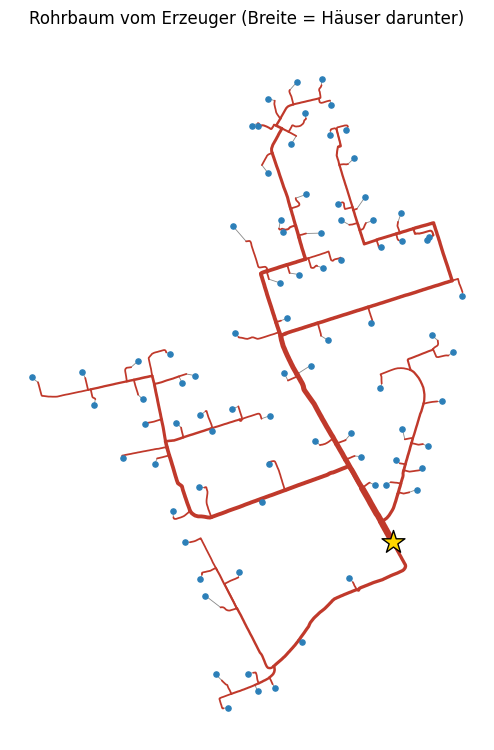

In [22]:
# Rohrbaum vom Erzeuger zu allen Häusern
if "vorlauf" not in globals():
    raise SystemExit("Erst die Kantentest-Zelle laufen lassen (sie definiert vorlauf() und MONATE).")

# nur Knoten mit Zähler (Verteiler ohne Zähler fliegen raus, der Erzeuger kommt separat über q_v)
haeuser = [n for n in G if n != QUELLE and n in nid and zaehler_von.get(n)]
ohne_daten = [n for n in haeuser if not any(z in serien for z in zaehler_von[n])]
print(f"Häuser mit Zähler: {len(haeuser)} | davon ohne Messdatei: {len(ohne_daten)} "
      f"| entfernt (ohne Zähler): {sum(1 for n in G if n != QUELLE and n in nid) - len(haeuser)}")
dist_q, pfade = nx.single_source_dijkstra(Gp, q_v, weight="len")

# 1) Baum: Wege vom Erzeuger zu allen Anschlussstellen
snap_von = {h: snap[nid[h]] for h in haeuser}
parent = {}
for s in set(snap_von.values()):
    p = pfade[s]
    for a, b in zip(p[:-1], p[1:]):
        parent[b] = a
kinder = {}
for b, a in parent.items():
    kinder.setdefault(a, []).append(b)
haus_an = {}
for h, s in snap_von.items():
    haus_an.setdefault(s, []).append(h)

# 2) Schlüsselpunkte: Erzeuger, Anschlussstellen, Verzweigungen
schluessel = {q_v} | set(haus_an) | {v for v, k in kinder.items() if len(k) >= 2}

# 3) Straßenabschnitte zwischen Schlüsselpunkten
T = nx.DiGraph()
for v in schluessel:
    T.add_node(v, art="quelle" if v == q_v else ("haus_stelle" if v in haus_an else "abzweig"))
for v in schluessel - {q_v}:
    weg = [v]
    u = parent[v]
    while u not in schluessel:
        weg.append(u)
        u = parent[u]
    weg.append(u)
    T.add_edge(u, v, laenge=dist_q[v] - dist_q[u], pfad=weg[::-1])
for u, v in T.edges:
    T[u][v]["n_haeuser"] = sum(len(haus_an.get(d, [])) for d in nx.descendants(T, v) | {v})

print(f"Baum: {T.number_of_nodes()} Schlüsselpunkte | {T.number_of_edges()} Abschnitte | "
      f"{sum(d['laenge'] for *_, d in T.edges(data=True)):.0f} m Rohr genutzt (von {sum(d['len'] for *_, d in Gp.edges(data=True)):.0f} m im Plan)")
print(f"Häuser: {len(haeuser)} | Anschlussstellen: {len(haus_an)} | Abzweige: {sum(1 for _, d in T.nodes(data=True) if d['art'] == 'abzweig')}")

# 4) Test gegen die Daten: ist das nächste Haus flussaufwärts wärmer?
def oberhaus(s):
    while s != q_v:
        s = next(T.predecessors(s))
        if s in haus_an:
            return haus_an[s]
    return []

zeilen = []
for h, s in snap_von.items():
    for o in oberhaus(s):
        a, b = vorlauf(o), vorlauf(h)
        if a is None or b is None:
            continue
        d = (a - b).dropna()
        if len(d) >= MIN_STUNDEN:
            zeilen.append({"oben": roh.get(o, o), "unten": roh.get(h, h), "median_K": round(d.median(), 2)})
            break
tt = pd.DataFrame(zeilen)
if len(tt):
    ok = int((tt.median_K > SCHWELLE_K).sum()); umg = int((tt.median_K < -SCHWELLE_K).sum())
    print(f"\nTest 'oberes Haus wärmer': bewertet {len(tt)} | ja: {ok} | nein: {umg} | unklar: {len(tt) - ok - umg}")
    display(tt.sort_values("median_K").head(10))

# 5) Bild
fig, ax = plt.subplots(figsize=(11, 9))
mx = max(d["n_haeuser"] for *_, d in T.edges(data=True))
for u, v, d in T.edges(data=True):
    P = np.array(d["pfad"])
    ax.plot(P[:, 0], P[:, 1], color="#c0392b", lw=0.8 + 4 * np.sqrt(d["n_haeuser"] / mx), solid_capstyle="round", zorder=2)
for h in haeuser:
    x, y = xy[nid[h]]
    sx, sy = snap_von[h]
    ax.plot([x, sx], [y, sy], color="#888", lw=0.6, zorder=1)
    ax.scatter([x], [y], s=14, color="#2c7fb8", zorder=3)
ax.scatter([q_v[0]], [q_v[1]], marker="*", s=300, color="gold", edgecolor="k", zorder=4)
ax.set_aspect("equal"); ax.axis("off")
ax.set_title("Rohrbaum vom Erzeuger (Breite = Häuser darunter)")
plt.savefig("rohrbaum.png", dpi=150, bbox_inches="tight"); plt.show()

In [9]:
nz_ = lambda s: str(s).strip().lower()

mit_zaehler = set(knoten["edge_node"])
zeilen = []
for n in G:
    zeilen.append({
        "node": n,
        "anzeige": roh.get(n, n),
        "hat_zaehler": n in mit_zaehler,
        "lat": round(pos[n][0], 6) if n in pos else None,
        "lon": round(pos[n][1], 6) if n in pos else None,
    })
t = pd.DataFrame(zeilen)
print(f"Nodes im Graphen: {len(t)} | mit Zähler: {int(t.hat_zaehler.sum())} | ohne Zähler: {int((~t.hat_zaehler).sum())}")
display(t[~t.hat_zaehler].to_string() if False else t[~t.hat_zaehler])

Nodes im Graphen: 111 | mit Zähler: 82 | ohne Zähler: 29


,node,anzeige,hat_zaehler,lat,lon
5,ginsterweg 24,Ginsterweg 24,False,49.801550,10.345195
8,ginsterweg 6,Ginsterweg 6,False,49.801408,10.346057
9,ginsterweg 14,Ginsterweg 14,False,49.801408,10.346057
12,anemonenweg 5,Anemonenweg 5,False,49.801092,10.345900
13,anemonenweg 4,Anemonenweg 4,False,49.801025,10.346075
16,mohnweg 21,Mohnweg 21,False,49.800788,10.345561
17,anemonenweg 1,Anemonenweg 1,False,49.800608,10.345974
29,irisweg 8,Irisweg 8,False,49.801378,10.346759
31,irisweg 6,Irisweg 6,False,49.801136,10.346840
32,irisweg 5,Irisweg 5,False,49.801000,10.346761


In [10]:
ERZEUGER_ADRESSE = "hans-zander-weg 14, 97353 Wiesentheid"     # bestätigte Adresse
NEU = "Quelle"

if QUELLE != NEU:
    nx.relabel_nodes(G, {QUELLE: NEU}, copy=False)      # Kanten bleiben erhalten
    pos[NEU] = pos.pop(QUELLE)
    roh.pop(QUELLE, None)
    QUELLE = NEU
roh[QUELLE] = ERZEUGER_ADRESSE

print(f"Knoten '{QUELLE}': {roh[QUELLE]} | {pos[QUELLE]} | führt zu {list(G.successors(QUELLE))}")

Knoten 'Quelle': hans-zander-weg 14, 97353 Wiesentheid | (49.797846, 10.347358) | führt zu ['hans-zander-weg 1']


In [17]:
import os
import numpy as np, pandas as pd, networkx as nx

START_ = pd.Timestamp(START) if "START" in globals() else pd.Timestamp("2024-01-01 00:00")
ENDE_ = pd.Timestamp(ENDE) if "ENDE" in globals() else pd.Timestamp("2025-05-31 23:00")
zeiten = pd.date_range(START_, ENDE_, freq="h")
FLUSS_MIN = 5.0          # l/h: darunter sind Vorlauf/Rücklauf nicht aussagekräftig
MERKMALE = ["vor", "rueck", "spreizung", "fluss", "leistung"]

hausliste = [h for h in haeuser if any(z in serien for z in zaehler_von.get(h, []))]

def reihe(h):
    ds = []
    for z in zaehler_von[h]:
        if z in serien:
            d = serien[z]
            ds.append(d[~d.index.duplicated()].reindex(zeiten))
    fl = pd.concat([d["fluss"] for d in ds], axis=1).sum(axis=1, min_count=1)
    le = pd.concat([d["leistung"] for d in ds], axis=1).sum(axis=1, min_count=1)
    ok = [d["fluss"] > FLUSS_MIN for d in ds]
    vo = pd.concat([d["vor"].where(o) for d, o in zip(ds, ok)], axis=1).mean(axis=1)
    rk = pd.concat([d["rueck"].where(o) for d, o in zip(ds, ok)], axis=1).mean(axis=1)
    return np.column_stack([vo, rk, vo - rk, fl, le])

X = np.stack([reihe(h) for h in hausliste], axis=1).astype("float32")      # (Zeit, Häuser, Merkmale)
print(f"Zeitreihen: {X.shape[0]} Stunden x {X.shape[1]} Häuser x {X.shape[2]} Merkmale")
print("Anteil gültiger Werte je Merkmal:", dict(zip(MERKMALE, np.round(np.mean(~np.isnan(X), axis=(0, 1)), 2))))

# Graph: Häuser (0..N-1) + Schlüsselpunkte des Rohrbaums T
N = len(hausliste)
tknoten = list(T.nodes)
tidx = {v: N + i for i, v in enumerate(tknoten)}
art = np.array([0] * N + [2 if v == q_v else 1 for v in tknoten])

def unter(v):
    return sum(len(haus_an.get(d, [])) for d in nx.descendants(T, v) | {v})

statisch = np.zeros((N + len(tknoten), 5), dtype="float32")   # rohrweg_m, tiefe, haeuser_unter, leistung_p99, anschluss_m
for i, h in enumerate(hausliste):
    s = snap_von[h]
    statisch[i] = [dist_q.get(s, np.nan), len(nx.ancestors(T, s)), 1,
                   np.nanpercentile(X[:, i, 4], 99) if np.isfinite(X[:, i, 4]).any() else np.nan,
                   float(dist_[nid[h]])]
for v in tknoten:
    statisch[tidx[v]] = [dist_q.get(v, 0.0), len(nx.ancestors(T, v)), unter(v), np.nan, 0.0]

kanten, kattr = [], []
for u, v, d in T.edges(data=True):
    kanten += [(tidx[u], tidx[v]), (tidx[v], tidx[u])]
    kattr += [(d["laenge"], 1.0, d["n_haeuser"]), (d["laenge"], -1.0, d["n_haeuser"])]
for i, h in enumerate(hausliste):
    s = tidx[snap_von[h]]
    a = float(dist_[nid[h]])
    kanten += [(s, i), (i, s)]
    kattr += [(a, 1.0, 1), (a, -1.0, 1)]
edge_index = np.array(kanten).T.astype("int64")
edge_attr = np.array(kattr, dtype="float32")         # laenge_m, richtung (+1 vom Erzeuger weg, -1 zum Erzeuger), haeuser_darunter

h_ = zeiten.hour.values; w_ = zeiten.dayofweek.values; d_ = zeiten.dayofyear.values
zeit_feat = np.column_stack([np.sin(2*np.pi*h_/24), np.cos(2*np.pi*h_/24),
                             np.sin(2*np.pi*w_/7), np.cos(2*np.pi*w_/7),
                             np.sin(2*np.pi*d_/366), np.cos(2*np.pi*d_/366)]).astype("float32")

os.makedirs("daten_cache", exist_ok=True)
np.savez_compressed("daten_cache/gnn_daten.npz", X=X, zeiten=zeiten.values.astype("datetime64[h]"),
                    hausliste=np.array([str(roh.get(h, h)) for h in hausliste]), art=art, statisch=statisch,
                    edge_index=edge_index, edge_attr=edge_attr, zeit_feat=zeit_feat,
                    merkmale=np.array(MERKMALE))
print(f"Graph: {N} Häuser + {len(tknoten)} Strecken-Knoten = {N + len(tknoten)} Knoten | {edge_index.shape[1]} gerichtete Kanten")
print("gespeichert: daten_cache/gnn_daten.npz")

Zeitreihen: 12408 Stunden x 82 Häuser x 5 Merkmale
Anteil gültiger Werte je Merkmal: {'vor': np.float64(0.57), 'rueck': np.float64(0.57), 'spreizung': np.float64(0.57), 'fluss': np.float64(0.89), 'leistung': np.float64(0.89)}
Graph: 82 Häuser + 154 Strecken-Knoten = 236 Knoten | 470 gerichtete Kanten
gespeichert: daten_cache/gnn_daten.npz


In [ ]:
# Repo-Ordner (enthält den Unterordner "src") suchen und in den Suchpfad legen
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "weather.py").exists()), None)
if ROOT is None:
    ROOT = Path(r"C:\Users\pauli\Documents\Information Systems\2026 SoSe\Projektseminar\projektseminar-1\src")      # <- hier den Repo-Ordner eintragen
sys.path.insert(0, str(ROOT))
print("Repo:", ROOT)

## Rohrbaum: Haus oder Netz?

**Frage:** Liegt eine Abweichung am einzelnen Haus oder am Netz? Idee: Ein Haus mit seinen Nachbarn im Rohrbaum vergleichen.

**Was wir gebaut haben**
- Rohrbaum von der Quelle zu den 110 Häusern. Die Quelle ist eine begründete Annahme.
- Kontrolle: Das obere Haus ist wärmer als das untere, bei 17 von 19 Paaren, bei keinem gegenläufig.

**Test** (79 Häuser, Daten vor dem 1.9.2024)
- Je Haus: Abweichung von seinem normalen Verhalten bei Außentemperatur und Tageszeit (Spreizung).
- Verglichen mit den 4 nächsten Nachbarn im Baum und mit zufälligen Häusern.

**Ergebnis**
- Alle Häuser schwanken gemeinsam (Korrelation ca. 0,36). Das ist ein Effekt im **ganzen Netz**.
- Nachbarn im Rohrbaum teilen nicht mehr als zufällige Häuser (0,37 gegen 0,36). Nach Abzug des Netz-Effekts bleibt fast nichts (0,03). Ein Effekt pro Strang ist **nicht nachweisbar**.
- Fehlererkennung mit Begehungslabels: nur **Ventil** liegt über Zufall (AUC ca. 0,65 bis 0,69, bei nur 10 Fällen unsicher). Der Nachbarvergleich bringt keine Verbesserung. Die übrigen Labels liegen bei Zufall.
- Das passt zum Ergebnis im Repo (NB 23: auffällige Stationen häufen sich im Netz nicht).

**Fazit:** Mit Tagesmitteln der Spreizung trennt der Rohrbaum „Haus oder Netz" nicht. Ein Abzug über alle Häuser reicht.

**Ideen für später**
1. Kurze Ereignisse (Stunden) statt Tagesmittel.
2. Sommernacht-Durchfluss für Ventil (im Repo AUC 0,89).
3. Andere Größen: Rücklauf, Vorlauf, Wärmeverlust pro 100 m.
4. Andere Nachbarschaft: alle Häuser unter demselben Abzweig.
5. Richtungstest: Folgen die Häuser unterhalb einem Haus, das oben abweicht?
6. GNN auf den Rohrbaum-Daten, erst wenn eine Größe mit Signal gefunden ist.
7. Unechte Abzweige durch parallele Vor-/Rücklaufleitungen zusammenführen.

**Grenzen:** Quelle und Richtungen sind Annahmen. Der Baum ist kein hydraulisches Modell. Wenige Fälle (9 bis 30 je Label), Begehungen zu zufälligen Terminen.

In [18]:
STICHTAG = pd.Timestamp("2024-09-01")     # nur Daten davor (wie in NB 18)
ZIEL = 2                                   # 0 vor, 1 rueck, 2 spreizung
K_NACHBARN = 4
MIN_TAGE = 30

# 1) Außentemperatur
from src.weather import load_outdoor_temperature
w = load_outdoor_temperature(zeiten[0], zeiten[-1]).set_index("timestamp")["t_out"]
t_out = w[~w.index.duplicated()].reindex(zeiten).interpolate(limit=6).to_numpy()

# 2) Residuum je Haus: eigene Regression auf Temperatur + Tageszeit (nur gültige Stunden)
F = np.column_stack([t_out, t_out**2, zeit_feat[:, :4]])
vor = zeiten < STICHTAG
res = np.full(X.shape[:2], np.nan, dtype="float32")
for i in range(X.shape[1]):
    y = X[:, i, ZIEL]
    ok = np.isfinite(y) & np.isfinite(F).all(1) & vor
    if ok.sum() < 24 * MIN_TAGE:
        continue
    m = Ridge(alpha=1.0).fit(F[ok], y[ok])
    res[ok, i] = y[ok] - m.predict(F[ok])

# 3) Tagesmittel + robuster z-Wert je Haus
rt = pd.DataFrame(res, index=zeiten).resample("D").mean()
rt = rt[rt.index < STICHTAG]
med, mad = rt.median(), (rt - rt.median()).abs().median() * 1.4826
Z = ((rt - med) / mad.replace(0, np.nan)).clip(-6, 6)          # (Tage, Häuser)

# 4) Nachbarn im Rohrbaum: nächste K Häuser nach Rohrweg
Tu = T.to_undirected()
snaps = [snap_von[h] for h in hausliste]
nachbarn = []
for i, s in enumerate(snaps):
    d = nx.single_source_dijkstra_path_length(Tu, s, weight="laenge")
    cand = sorted((d.get(snaps[j], np.inf), j) for j in range(len(snaps)) if j != i)
    nachbarn.append([j for _, j in cand[:K_NACHBARN]])

# 5) Haus vs. Netz
zi = Z.to_numpy()
nz = np.full_like(zi, np.nan)
for i, nb in enumerate(nachbarn):
    sub = zi[:, nb]
    n_ok = np.isfinite(sub).sum(1)
    nz[:, i] = np.where(n_ok >= 2, np.nanmean(sub, axis=1), np.nan)
e = zi - nz                                                    # Haus-spezifischer Anteil
tab = pd.DataFrame({
    "haus": [roh.get(h, h) for h in hausliste],
    "tage": np.isfinite(zi).sum(0),
    "roh_abw": np.nanmean(np.abs(zi), axis=0),                 # ohne Nachbarn
    "haus_abw": np.nanmean(np.abs(e), axis=0),                 # nach Abzug der Nachbarn
    "netz_abw": np.nanmean(np.abs(nz), axis=0),                # Anteil, den die Nachbarn teilen
    "haus_tage": np.nanmean(np.abs(e) > 2, axis=0),
    "netz_tage": np.nanmean(np.abs(nz) > 1.5, axis=0),
})
tab["zaehler"] = [zaehler_von[h][0] for h in hausliste]
tab = tab[tab.tage >= MIN_TAGE]
print(f"{len(tab)} Häuser bewertet | Netzanteil der Abweichung (Mittel): "
      f"{(tab.netz_abw / tab.roh_abw).mean():.0%}")
print(tab.sort_values("haus_abw", ascending=False).head(10).round(2).to_string(index=False))

# 6) Prüfung gegen Begehungslabels (Positiv/unbekannt)
pfad = next(p for p in [Path("data/processed/modell_labels.csv"), Path("../data/processed/modell_labels.csv"),
                        *Path("..").rglob("modell_labels.csv")] if p.exists())
lab = pd.read_csv(pfad, index_col=0)
lab.index = lab.index.astype(str)
print("Label-Spalten:", list(lab.columns))
mm = tab.assign(zaehler=tab.zaehler.astype(str)).merge(lab, left_on="zaehler", right_index=True)
print(f"{len(mm)} bewertete Häuser mit Begehung")
zeilen = []
for c in lab.columns:
    y = pd.to_numeric(mm[c], errors="coerce")
    if set(y.dropna().unique()) <= {0, 1} and 4 <= y.sum() < y.notna().sum():
        zeilen.append({"label": c, "positive": int(y.sum()), "n": int(y.notna().sum()),
                       **{s: round(roc_auc_score(y[y.notna()], mm.loc[y.notna(), s]), 2)
                          for s in ["roh_abw", "haus_abw", "netz_abw"]}})
print(pd.DataFrame(zeilen).to_string(index=False))

C:\Users\pauli\AppData\Local\Temp\ipykernel_11212\1626583837.py:49: RuntimeWarning: Mean of empty slice
  "roh_abw": np.nanmean(np.abs(zi), axis=0),                 # ohne Nachbarn
C:\Users\pauli\AppData\Local\Temp\ipykernel_11212\1626583837.py:50: RuntimeWarning: Mean of empty slice
  "haus_abw": np.nanmean(np.abs(e), axis=0),                 # nach Abzug der Nachbarn


79 Häuser bewertet | Netzanteil der Abweichung (Mittel): 79%
            haus  tage  roh_abw  haus_abw  netz_abw  haus_tage  netz_tage  zaehler
 Blütenstraße 11   244     1.52      1.58      0.79       0.23       0.11 68956351
    Asternweg 18   195     1.08      1.56      0.82       0.20       0.14 68956365
   Anemonenweg 8   239     1.32      1.41      0.77       0.24       0.14 72135463
    Asternweg 27   207     0.96      1.33      0.68       0.21       0.07 80912172
Fliederstraße 28   114     1.06      1.31      0.67       0.11       0.08 80912156
  Rosenstraße 15   244     1.05      1.31      0.66       0.25       0.12 72167777
     Krokusweg 2   244     1.16      1.26      0.90       0.20       0.22 72167793
      Irisweg 11   244     1.10      1.25      0.87       0.18       0.18 68956372
Fliederstraße 26   191     1.04      1.18      0.69       0.14       0.08 80912164
   Anemonenweg 3   244     1.24      1.12      0.65       0.13       0.09 72167782
Label-Spalten: ['begehunge

In [19]:
rng = np.random.default_rng(0)
ok_h = [i for i in range(zi.shape[1]) if np.isfinite(zi[:, i]).sum() >= MIN_TAGE]

def korr(a, b):
    m = np.isfinite(a) & np.isfinite(b)
    return np.corrcoef(a[m], b[m])[0, 1] if m.sum() >= MIN_TAGE else np.nan

echt = np.array([np.nanmean([korr(zi[:, i], zi[:, j]) for j in nachbarn[i]]) for i in ok_h])
zuf = np.array([[np.nanmean([korr(zi[:, i], zi[:, j]) for j in rng.choice([k for k in ok_h if k != i], K_NACHBARN, replace=False)])
                 for i in ok_h] for _ in range(200)])
print(f"Korrelation mit den Rohrbaum-Nachbarn: Mittel {np.nanmean(echt):.3f}")
print(f"Korrelation mit zufälligen Häusern:     Mittel {np.nanmean(zuf):.3f}  (95 %: {np.nanpercentile(np.nanmean(zuf,1),95):.3f})")
print(f"Anteil Häuser mit Nachbar-Korrelation über 0,3: {np.nanmean(echt > 0.3):.0%}")

Korrelation mit den Rohrbaum-Nachbarn: Mittel 0.367
Korrelation mit zufälligen Häusern:     Mittel 0.361  (95 %: 0.378)
Anteil Häuser mit Nachbar-Korrelation über 0,3: 72%


In [20]:
# netzweites Signal je Tag (ohne das Haus selbst) abziehen
glob = np.full_like(zi, np.nan)
for i in range(zi.shape[1]):
    glob[:, i] = np.nanmedian(np.delete(zi, i, axis=1), axis=1)
eg = zi - glob                                    # Haus-spezifisch nach Abzug des Netzsignals

# 1) teilen die Rohrbaum-Nachbarn nach diesem Abzug noch etwas?
echt2 = np.array([np.nanmean([korr(eg[:, i], eg[:, j]) for j in nachbarn[i]]) for i in ok_h])
zuf2 = np.array([[np.nanmean([korr(eg[:, i], eg[:, j]) for j in rng.choice([k for k in ok_h if k != i], K_NACHBARN, replace=False)])
                  for i in ok_h] for _ in range(200)])
print(f"nach Netzabzug - Nachbarn: {np.nanmean(echt2):.3f} | zufällig: {np.nanmean(zuf2):.3f} "
      f"(95 %: {np.nanpercentile(np.nanmean(zuf2,1),95):.3f})")

# 2) AUC mit Netzabzug statt Nachbarabzug
tab["haus_netzabzug"] = np.nanmean(np.abs(eg), axis=0)[[hausliste.index(h) for h in hausliste]][:len(tab)] if False else \
    pd.Series(np.nanmean(np.abs(eg), axis=0), index=range(zi.shape[1])).reindex(tab.index).to_numpy()
mm2 = tab.assign(zaehler=tab.zaehler.astype(str)).merge(lab, left_on="zaehler", right_index=True)
zeilen = []
for c in lab.columns:
    y = pd.to_numeric(mm2[c], errors="coerce")
    if set(y.dropna().unique()) <= {0, 1} and 4 <= y.sum() < y.notna().sum():
        zeilen.append({"label": c, "positive": int(y.sum()),
                       **{s: round(roc_auc_score(y[y.notna()], mm2.loc[y.notna(), s]), 2)
                          for s in ["roh_abw", "haus_abw", "haus_netzabzug"]}})
print(pd.DataFrame(zeilen).to_string(index=False))

nach Netzabzug - Nachbarn: 0.034 | zufällig: 0.013 (95 %: 0.028)
             label  positive  roh_abw  haus_abw  haus_netzabzug
            ventil        10     0.64      0.68            0.69
          daemmung        19     0.41      0.37            0.38
            filter        20     0.39      0.46            0.46
        durchfluss        17     0.45      0.52            0.51
        temperatur        30     0.50      0.56            0.55
ueberdimensioniert         9     0.36      0.39            0.45


C:\Users\pauli\AppData\Local\Temp\ipykernel_11212\2077108403.py:16: RuntimeWarning: Mean of empty slice
  pd.Series(np.nanmean(np.abs(eg), axis=0), index=range(zi.shape[1])).reindex(tab.index).to_numpy()


In [32]:
# Ideen 4+5+1: gleicher Abzweig, Richtungstest, kurze Ereignisse (Haus oder Netz)
N_H = len(hausliste)
def mittel(daten, gruppe):
    c = [korr(daten[:, a], daten[:, b]) for ii, a in enumerate(gruppe) for b in gruppe[ii + 1:]]
    return np.nanmean(c) if c else np.nan

# --- Idee 4: Häuser unter demselben Abzweig (gleicher Vorgänger im Baum)
eltern = {}
for i, s in enumerate(snaps):
    p = next(iter(T.predecessors(s)), None)
    eltern.setdefault(p, []).append(i)
gruppen = [[i for i in g if i in set(ok_h)] for g in eltern.values()]
gruppen = [g for g in gruppen if len(g) >= 2]
print(f"\n4) Gruppen unter demselben Abzweig: {len(gruppen)} Gruppen, Größen {sorted(map(len, gruppen))[-5:]}...")
for name, daten in [("Tagesabweichung", zi), ("nach Netzabzug", eg)]:
    echt = np.nanmean([mittel(daten, g) for g in gruppen])
    zuf = [np.nanmean([mittel(daten, list(rng.choice(ok_h, len(g), replace=False))) for g in gruppen]) for _ in range(200)]
    print(f"   {name:16s} echt {echt:.3f} | zufällige Gruppen {np.mean(zuf):.3f} (95 %: {np.percentile(zuf, 95):.3f})")

# --- Stundenresiduen für 5 und 1
Rh = pd.DataFrame(res).sub(pd.DataFrame(res).median(axis=1), axis=0)
Rh = Rh - Rh.shift(1) * Rh.apply(lambda s: s.autocorr(1))
Zh = ((Rh - Rh.median()) / ((Rh - Rh.median()).abs().median() * 1.4826)).clip(-8, 8).to_numpy()

# --- Idee 5: Richtungstest. a oberhalb b im Baum: folgt b dem a mit 1-3 h Versatz mehr als umgekehrt?
def vk(a, b, l):
    x, y = Zh[:-l, a], Zh[l:, b]
    m = np.isfinite(x) & np.isfinite(y)
    return np.corrcoef(x[m], y[m])[0, 1] if m.sum() > 24 * MIN_TAGE else np.nan
okset = set(ok_h)
paare_ab = [(a, b) for a in ok_h for b in ok_h if a != b and snaps[a] != snaps[b] and nx.has_path(T, snaps[a], snaps[b])]
if len(paare_ab) > 400:
    paare_ab = [paare_ab[i] for i in rng.choice(len(paare_ab), 400, replace=False)]
d = []
for a, b in paare_ab:
    d.append(max(vk(a, b, l) for l in (1, 2, 3)) - max(vk(b, a, l) for l in (1, 2, 3)))
d = np.array(d); d = d[np.isfinite(d)]
vz = rng.choice([-1, 1], size=(2000, len(d)))
p = np.mean(np.abs((vz * d).mean(1)) >= abs(d.mean()))
print(f"\n5) Richtung: {len(d)} Paare 'a oben, b unten'. Mittlere Differenz (oben->unten minus unten->oben) {d.mean():+.4f}, "
      f"Anteil positiv {np.mean(d > 0):.0%} (Zufall 50 %), p = {p:.2f}")

# --- Idee 1: kurze Ereignisse (mind. 3 Stunden in Folge |z| > 3), Haus oder Netz?
ereignis = np.zeros(Zh.shape, dtype=bool)
hoch = np.abs(np.nan_to_num(Zh)) > 3
lauf = hoch[:-2] & hoch[1:-1] & hoch[2:]
ereignis[2:] = lauf
tage_idx = pd.Series(zeiten).dt.floor("D")
tagE = pd.DataFrame(ereignis, columns=range(Zh.shape[1])).groupby(tage_idx.values).any().to_numpy()
n_ereig = tagE.sum()
anteil = tagE[:, [i for i in ok_h if i < tagE.shape[1]]].mean(1)
netztag = anteil > 0.25
print(f"\n1) Ereignisse (>=3 h in Folge |z|>3): {n_ereig} Haus-Tage mit Ereignis in {tagE.shape[0]} Tagen; "
      f"Netztage (>25 % der Häuser): {netztag.sum()}, darin {tagE[netztag].sum() / max(n_ereig, 1):.0%} aller Ereignisse")
E_ = tagE[~netztag]
tab_n, tab_z = [], []
for i in ok_h:
    if E_[:, i].sum() == 0:
        continue
    tage = E_[:, i]
    nb_i = [j for j in nachbarn[i] if j in okset]
    zuf_j = [j for j in ok_h if j != i]
    tab_n.append(E_[tage][:, nb_i].mean())
    tab_z.append(E_[tage][:, zuf_j].mean())
print(f"   außerhalb der Netztage: Wenn ein Haus ein Ereignis hat, haben es auch {np.mean(tab_n):.1%} seiner Rohrbaum-Nachbarn "
      f"am selben Tag (alle anderen Häuser: {np.mean(tab_z):.1%})")


4) Gruppen unter demselben Abzweig: 12 Gruppen, Größen [2, 2, 2, 2, 2]...
   Tagesabweichung  echt 0.576 | zufällige Gruppen 0.357 (95 %: 0.465)
   nach Netzabzug   echt 0.156 | zufällige Gruppen 0.014 (95 %: 0.102)

5) Richtung: 35 Paare 'a oben, b unten'. Mittlere Differenz (oben->unten minus unten->oben) -0.0027, Anteil positiv 51% (Zufall 50 %), p = 0.62

1) Ereignisse (>=3 h in Folge |z|>3): 280 Haus-Tage mit Ereignis in 517 Tagen; Netztage (>25 % der Häuser): 0, darin 0% aller Ereignisse
   außerhalb der Netztage: Wenn ein Haus ein Ereignis hat, haben es auch 2.0% seiner Rohrbaum-Nachbarn am selben Tag (alle anderen Häuser: 2.7%)


In [33]:
# Ideen 2+3: Sommernacht-Durchfluss und andere Zielgrößen, jeweils AUC mit Unsicherheitsbereich
lab_h = lab.reindex([str(zaehler_von[h][0]) for h in hausliste]); lab_h.index = range(len(hausliste))
LABELS = [c for c in lab.columns if c not in ("begehungen", "erste_begehung", "strasse_gruppe")]

def auc_ci(y, s, n=400):
    d = pd.DataFrame({"y": y, "s": s}).dropna()
    if d.y.sum() < 4 or d.y.sum() == len(d):
        return np.nan, np.nan, np.nan
    a = roc_auc_score(d.y, d.s)
    r = np.random.default_rng(0); bs = []
    for _ in range(n):
        b = d.iloc[r.integers(0, len(d), len(d))]
        if 0 < b.y.sum() < len(b):
            bs.append(roc_auc_score(b.y, b.s))
    return a, *np.percentile(bs, [5, 95])

def tabelle(scores):
    zeilen = []
    for lname in LABELS:
        y = pd.to_numeric(lab_h[lname], errors="coerce")
        if not set(y.dropna().unique()) <= {0, 1}:
            continue
        for sname, s in scores.items():
            a, lo, hi = auc_ci(y, pd.Series(s, index=range(len(s))))
            if not np.isnan(a):
                zeilen.append({"label": lname, "score": sname, "AUC": round(a, 2), "90%-Bereich": f"{lo:.2f}-{hi:.2f}"})
    return pd.DataFrame(zeilen)

# --- Sommernacht (Jun-Aug 2024, 0-4 Uhr)
nacht = (zeiten.month.isin([6, 7, 8])) & (zeiten.year == 2024) & (zeiten.hour < 5)
tag = (zeiten.month.isin([6, 7, 8])) & (zeiten.year == 2024) & (zeiten.hour >= 12) & (zeiten.hour < 18)
fl = X[:, :, 3]
nacht_mittel = np.nanmean(fl[nacht], axis=0)
nacht_median = np.nanmedian(fl[nacht], axis=0)
nacht_aktiv = np.nanmean(np.where(np.isfinite(fl[nacht]), fl[nacht] > FLUSS_MIN, np.nan), axis=0)
tag_mittel = np.nanmean(fl[tag], axis=0)
scores = {"nacht_mittel": nacht_mittel, "nacht_median": nacht_median, "nacht_aktiv": nacht_aktiv,
          "nacht/tag": nacht_mittel / np.where(tag_mittel > 0, tag_mittel, np.nan)}
sn = tabelle(scores)
print("Sommernacht-Durchfluss:"); print(sn[sn.label.isin(["ventil", "ueberdimensioniert", "durchfluss"])].to_string(index=False))

# --- andere Zielgrößen: Tagesabweichung (roh) und nach Netzabzug (ohne Nachbarn)
def tagesz(ziel):
    out = np.full(X.shape[:2], np.nan, dtype="float32")
    for i in range(X.shape[1]):
        y = X[:, i, ziel]
        ok = np.isfinite(y) & np.isfinite(F).all(1) & vor
        if ok.sum() < 24 * MIN_TAGE:
            continue
        out[ok, i] = y[ok] - Ridge(alpha=1.0).fit(F[ok], y[ok]).predict(F[ok])
    rt_ = pd.DataFrame(out, index=zeiten).resample("D").mean()
    rt_ = rt_[rt_.index < STICHTAG]
    m_ = (rt_ - rt_.median()).abs().median() * 1.4826
    return ((rt_ - rt_.median()) / m_.replace(0, np.nan)).clip(-6, 6).to_numpy()

scores = {}
for ziel, name in [(0, "vor"), (1, "rueck"), (2, "spreizung")]:
    z_ = tagesz(ziel)
    g_ = np.column_stack([np.nanmedian(np.delete(z_, i, axis=1), axis=1) for i in range(z_.shape[1])])
    with np.errstate(all="ignore"):
        scores[f"{name}_roh"] = np.nanmean(np.abs(z_), axis=0)
        scores[f"{name}_netzabzug"] = np.nanmean(np.abs(z_ - g_), axis=0)
        scores[f"{name}_zu_hoch"] = np.nanmean(z_ - g_, axis=0)          # Vorzeichen: dauerhaft über Netz
tz = tabelle(scores)
print("\nZielgrößen (beste je Label):")
print(tz.sort_values("AUC", ascending=False).groupby("label").head(3).sort_values(["label", "AUC"], ascending=[True, False]).to_string(index=False))

# --- Vorlauf-Defizit entlang des Rohrwegs (Wärmeverlust grob): Jan-Feb 2024, nur Stunden mit Durchfluss
winter = (zeiten.year == 2024) & (zeiten.month.isin([1, 2]))
vor_w = np.nanmedian(np.where(fl[winter] > FLUSS_MIN, X[winter][:, :, 0], np.nan), axis=0)
rohrweg = statisch[:len(hausliste), 0]
g_ok = np.isfinite(vor_w) & np.isfinite(rohrweg)
k = np.polyfit(rohrweg[g_ok], vor_w[g_ok], 1)
print(f"\nVorlauf Jan-Feb: {k[0] * 100:+.2f} K je 100 m Rohrweg")
defizit = vor_w - np.polyval(k, rohrweg)
print(tabelle({"vorlauf_zu_niedrig": -defizit, "vorlauf_abw": np.abs(defizit)}).to_string(index=False))

C:\Users\pauli\AppData\Local\Temp\ipykernel_11212\245725825.py:33: RuntimeWarning: Mean of empty slice
  nacht_mittel = np.nanmean(fl[nacht], axis=0)
C:\Users\pauli\AppData\Local\Temp\ipykernel_11212\245725825.py:34: RuntimeWarning: All-NaN slice encountered
  nacht_median = np.nanmedian(fl[nacht], axis=0)
C:\Users\pauli\AppData\Local\Temp\ipykernel_11212\245725825.py:35: RuntimeWarning: Mean of empty slice
  nacht_aktiv = np.nanmean(np.where(np.isfinite(fl[nacht]), fl[nacht] > FLUSS_MIN, np.nan), axis=0)
C:\Users\pauli\AppData\Local\Temp\ipykernel_11212\245725825.py:36: RuntimeWarning: Mean of empty slice
  tag_mittel = np.nanmean(fl[tag], axis=0)


Sommernacht-Durchfluss:
             label        score  AUC 90%-Bereich
            ventil nacht_mittel 0.82   0.64-0.98
            ventil nacht_median 0.86   0.71-0.99
            ventil  nacht_aktiv 0.85   0.70-0.97
            ventil    nacht/tag 0.68   0.51-0.85
        durchfluss nacht_mittel 0.47   0.33-0.61
        durchfluss nacht_median 0.48   0.36-0.60
        durchfluss  nacht_aktiv 0.48   0.33-0.61
        durchfluss    nacht/tag 0.43   0.28-0.57
ueberdimensioniert nacht_mittel 0.54   0.32-0.72
ueberdimensioniert nacht_median 0.51   0.37-0.66
ueberdimensioniert  nacht_aktiv 0.57   0.39-0.73
ueberdimensioniert    nacht/tag 0.58   0.40-0.77


C:\Users\pauli\AppData\Local\Temp\ipykernel_11212\245725825.py:61: RuntimeWarning: Mean of empty slice
  scores[f"{name}_roh"] = np.nanmean(np.abs(z_), axis=0)
C:\Users\pauli\AppData\Local\Temp\ipykernel_11212\245725825.py:62: RuntimeWarning: Mean of empty slice
  scores[f"{name}_netzabzug"] = np.nanmean(np.abs(z_ - g_), axis=0)
C:\Users\pauli\AppData\Local\Temp\ipykernel_11212\245725825.py:63: RuntimeWarning: Mean of empty slice
  scores[f"{name}_zu_hoch"] = np.nanmean(z_ - g_, axis=0)          # Vorzeichen: dauerhaft über Netz
C:\Users\pauli\AppData\Local\Temp\ipykernel_11212\245725825.py:61: RuntimeWarning: Mean of empty slice
  scores[f"{name}_roh"] = np.nanmean(np.abs(z_), axis=0)
C:\Users\pauli\AppData\Local\Temp\ipykernel_11212\245725825.py:62: RuntimeWarning: Mean of empty slice
  scores[f"{name}_netzabzug"] = np.nanmean(np.abs(z_ - g_), axis=0)
C:\Users\pauli\AppData\Local\Temp\ipykernel_11212\245725825.py:63: RuntimeWarning: Mean of empty slice
  scores[f"{name}_zu_hoch"] = n


Zielgrößen (beste je Label):
             label               score  AUC 90%-Bereich
          daemmung         vor_zu_hoch 0.56   0.40-0.69
          daemmung       rueck_zu_hoch 0.55   0.40-0.71
          daemmung   spreizung_zu_hoch 0.52   0.36-0.66
        durchfluss       rueck_zu_hoch 0.54   0.41-0.69
        durchfluss       vor_netzabzug 0.53   0.39-0.66
        durchfluss   spreizung_zu_hoch 0.53   0.37-0.68
            filter   spreizung_zu_hoch 0.53   0.39-0.67
            filter       vor_netzabzug 0.47   0.33-0.60
            filter             vor_roh 0.46   0.31-0.60
        temperatur     rueck_netzabzug 0.63   0.48-0.77
        temperatur           rueck_roh 0.62   0.46-0.76
        temperatur spreizung_netzabzug 0.55   0.42-0.69
ueberdimensioniert   spreizung_zu_hoch 0.69   0.45-0.87
ueberdimensioniert           rueck_roh 0.59   0.42-0.77
ueberdimensioniert     rueck_netzabzug 0.52   0.35-0.73
            ventil   spreizung_zu_hoch 0.79   0.65-0.93
            ventil

c:\Users\pauli\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a, func=_nanmedian, keepdims=keepdims,


             label              score  AUC 90%-Bereich
            ventil vorlauf_zu_niedrig 0.19   0.09-0.30
            ventil        vorlauf_abw 0.48   0.28-0.69
          daemmung vorlauf_zu_niedrig 0.56   0.39-0.69
          daemmung        vorlauf_abw 0.66   0.52-0.78
            filter vorlauf_zu_niedrig 0.36   0.23-0.50
            filter        vorlauf_abw 0.45   0.30-0.60
        durchfluss vorlauf_zu_niedrig 0.48   0.33-0.60
        durchfluss        vorlauf_abw 0.47   0.33-0.64
        temperatur vorlauf_zu_niedrig 0.45   0.32-0.57
        temperatur        vorlauf_abw 0.50   0.36-0.64
ueberdimensioniert vorlauf_zu_niedrig 0.57   0.36-0.76
ueberdimensioniert        vorlauf_abw 0.51   0.30-0.71


In [34]:
for g in gruppen:
    if len(g) == 2:
        a, b = g
        print(snaps[a] == snaps[b], round(korr(eg[:, a], eg[:, b]), 2),
              round(statisch[a, 4], 0), round(statisch[b, 4], 0))

False 0.12 7.0 5.0
False 0.25 6.0 2.0
False 0.34 3.0 4.0
False -0.03 8.0 6.0
False 0.6 16.0 8.0
False 0.34 7.0 3.0
False -0.1 7.0 9.0
False -0.23 7.0 8.0
False -0.13 8.0 6.0
False 0.36 6.0 6.0
False 0.27 8.0 4.0
False 0.08 5.0 5.0


In [36]:
# Basislinie: Logistische Regression mit Straßen-CV, mit und ohne Graph-Merkmale


# Merkmale je Haus (alles nur aus Daten vor dem Stichtag)
def hoch_gegen_netz(ziel):
    z_ = tagesz(ziel)
    g_ = np.column_stack([np.nanmedian(np.delete(z_, i, axis=1), axis=1) for i in range(z_.shape[1])])
    with np.errstate(all="ignore"):
        return np.nanmean(z_ - g_, axis=0)

nb_mittel = lambda w: np.array([np.nanmean(w[[j for j in nachbarn[i]]]) if len(nachbarn[i]) else np.nan
                                for i in range(len(w))])
merk = pd.DataFrame({
    "nacht_median": nacht_median, "nacht_aktiv": nacht_aktiv,
    "spreizung_hoch": hoch_gegen_netz(2), "vor_hoch": hoch_gegen_netz(0), "rueck_hoch": hoch_gegen_netz(1),
    "vorlauf_defizit": defizit,
})
graph = pd.DataFrame({"nb_nacht": nb_mittel(nacht_median), "nb_spreizung": nb_mittel(merk.spreizung_hoch.to_numpy())})
graph["nacht_minus_nb"] = merk.nacht_median - graph.nb_nacht
graph["spreizung_minus_nb"] = merk.spreizung_hoch - graph.nb_spreizung

MODELLE = {
    "Nachtfluss allein (kein Training)": None,
    "LR: Nachtfluss (2)":               ["nacht_median", "nacht_aktiv"],
    "LR: alle Haus-Merkmale (6)":       list(merk.columns),
    "LR: Haus + Graph (10)":            list(merk.columns) + list(graph.columns),
}
alle = pd.concat([merk, graph], axis=1)
gruppe = lab_h["strasse_gruppe"] if "strasse_gruppe" in lab_h else pd.Series(range(len(lab_h)))

def modell():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                         LogisticRegression(C=0.3, class_weight="balanced", max_iter=1000))

def cv_auc(cols, y, g, wiederholungen=20):
    aucs = []
    for r in range(wiederholungen):
        oof = pd.Series(np.nan, index=y.index)
        for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=r).split(alle.loc[y.index], y, g.loc[y.index]):
            m = modell().fit(alle.loc[y.index[tr], cols], y.iloc[tr])
            oof.iloc[te] = m.predict_proba(alle.loc[y.index[te], cols])[:, 1]
        aucs.append(roc_auc_score(y, oof))
    return np.mean(aucs), np.percentile(aucs, 5), np.percentile(aucs, 95)

zeilen = []
for lname in [c for c in LABELS if lab_h[c].notna().sum() > 0]:
    y = pd.to_numeric(lab_h[lname], errors="coerce").dropna()
    y = y[y.index.isin(alle.index) & merk.nacht_median.reindex(y.index).notna()]
    if y.sum() < 8 or y.sum() > len(y) - 8:
        continue
    for name, cols in MODELLE.items():
        if cols is None:
            a, lo, hi = auc_ci(y, merk.nacht_median.reindex(y.index))
            zeilen.append({"label": lname, "positive": int(y.sum()), "n": len(y), "modell": name,
                           "AUC": round(a, 2), "Streuung": f"{lo:.2f}-{hi:.2f} (Bootstrap)"})
        else:
            a, lo, hi = cv_auc(cols, y, gruppe)
            zeilen.append({"label": lname, "positive": int(y.sum()), "n": len(y), "modell": name,
                           "AUC": round(a, 2), "Streuung": f"{lo:.2f}-{hi:.2f} (20x Straßen-CV)"})
ergebnis = pd.DataFrame(zeilen)
print(ergebnis.to_string(index=False))

# Koeffizienten des Ventil-Modells (zur Kontrolle der Richtung)
y = pd.to_numeric(lab_h["ventil"], errors="coerce").dropna()
y = y[merk.nacht_median.reindex(y.index).notna()]
m = modell().fit(alle.loc[y.index, list(merk.columns)], y)
print("\nKoeffizienten Ventil (standardisiert, + = spricht für Ventil):")
print(pd.Series(m[-1].coef_[0], index=merk.columns).round(2).sort_values().to_string())

C:\Users\pauli\AppData\Local\Temp\ipykernel_11212\2946451217.py:9: RuntimeWarning: Mean of empty slice
  return np.nanmean(z_ - g_, axis=0)
C:\Users\pauli\AppData\Local\Temp\ipykernel_11212\2946451217.py:9: RuntimeWarning: Mean of empty slice
  return np.nanmean(z_ - g_, axis=0)
C:\Users\pauli\AppData\Local\Temp\ipykernel_11212\2946451217.py:9: RuntimeWarning: Mean of empty slice
  return np.nanmean(z_ - g_, axis=0)


             label  positive  n                            modell  AUC                   Streuung
            ventil        10 50 Nachtfluss allein (kein Training) 0.86      0.71-0.99 (Bootstrap)
            ventil        10 50                LR: Nachtfluss (2) 0.81 0.81-0.82 (20x Straßen-CV)
            ventil        10 50        LR: alle Haus-Merkmale (6) 0.88 0.87-0.88 (20x Straßen-CV)
            ventil        10 50             LR: Haus + Graph (10) 0.86 0.86-0.86 (20x Straßen-CV)
          daemmung        19 50 Nachtfluss allein (kein Training) 0.53      0.41-0.64 (Bootstrap)
          daemmung        19 50                LR: Nachtfluss (2) 0.44 0.39-0.49 (20x Straßen-CV)
          daemmung        19 50        LR: alle Haus-Merkmale (6) 0.55 0.51-0.60 (20x Straßen-CV)
          daemmung        19 50             LR: Haus + Graph (10) 0.62 0.57-0.69 (20x Straßen-CV)
            filter        21 50 Nachtfluss allein (kein Training) 0.44      0.33-0.56 (Bootstrap)
            filter  

In [29]:
# Gelernter Graph aus Zeitreihen: zeitversetzte Korrelation der Stundenresiduen
MAX_VERSATZ = 3          # Stunden
N_PERM = 200
SCHWELLE_Q = 99.5        # Perzentil der Zufallsverteilung (zirkulare Verschiebung)

# 1) Stundenresiduen: netzweiten Median je Stunde abziehen, dann AR(1) entfernen (gegen Scheinkorrelation)
R = pd.DataFrame(res)
N_FAKTOREN = 3
R0 = R.sub(R.median(axis=1), axis=0)
A = R0.fillna(0).to_numpy()
U, S, Vt = np.linalg.svd(A - A.mean(0), full_matrices=False)
print("Anteil der Varianz der ersten Faktoren:", np.round(S[:6]**2 / np.sum(S**2), 3))
gemeinsam = (U[:, :N_FAKTOREN] * S[:N_FAKTOREN]) @ Vt[:N_FAKTOREN]
R = R0 - gemeinsam + (A - A.mean(0) - (A - A.mean(0)))   # NaN-Stellen bleiben unten wieder leer
R = R.where(R0.notna())
gut = [i for i in range(R.shape[1]) if R.iloc[:, i].notna().sum() >= 24 * MIN_TAGE]
R = R.iloc[:, gut]
rho = R.apply(lambda s: s.autocorr(1))
R = R - R.shift(1) * rho
Zs = ((R - R.mean()) / R.std()).to_numpy()
M = np.isfinite(Zs).astype(float)
Z0 = np.nan_to_num(Zs)

def versatz_korr(Z0, M, l):
    n = M[:-l].T @ M[l:]
    c = (Z0[:-l].T @ Z0[l:]) / np.maximum(n, 1)
    c[n < 24 * MIN_TAGE] = 0
    return c                                  # c[a, b] = Korrelation a(t) mit b(t+l)

def staerkste(Z0, M):
    return np.max([np.abs(versatz_korr(Z0, M, l)) for l in range(1, MAX_VERSATZ + 1)], axis=0)

C = staerkste(Z0, M)
np.fill_diagonal(C, 0)

# 2) Zufallsgrenze: jede Reihe um eine eigene zufällige Zeit verschieben (Autokorrelation bleibt)
rng2 = np.random.default_rng(1)
T_ = Z0.shape[0]
null = []
for _ in range(N_PERM):
    sh = 24 * rng2.integers(7, (T_ - 24 * 7) // 24, size=Z0.shape[1])    
    Zp = np.column_stack([np.roll(Z0[:, k], sh[k]) for k in range(Z0.shape[1])])
    Mp = np.column_stack([np.roll(M[:, k], sh[k]) for k in range(Z0.shape[1])])
    Cp = staerkste(Zp, Mp); np.fill_diagonal(Cp, 0)
    null.append(Cp[np.triu_indices_from(Cp, 1)])
grenze = np.percentile(np.concatenate(null), SCHWELLE_Q)
kanten_gel = np.argwhere(C > grenze)
n_paare = len(gut) * (len(gut) - 1)
print(f"{len(gut)} Häuser | Grenze |r| > {grenze:.3f} | gelernte Kanten: {len(kanten_gel)} von {n_paare} "
      f"(zufällig erwartet ca. {(100 - SCHWELLE_Q) / 100 * n_paare:.0f})")

# 3) Passen die gelernten Kanten zu Rohrbaum / Kantendatei?
orig = np.array(gut)
def als_menge(paare):
    return {frozenset(p) for p in paare}
gel = als_menge((orig[a], orig[b]) for a, b in kanten_gel)
baum = als_menge((i, j) for i in range(len(hausliste)) for j in nachbarn[i])
alle = als_menge((orig[a], orig[b]) for a in range(len(gut)) for b in range(a + 1, len(gut)))
def treffer(name, ref):
    ref = ref & alle
    quote = len(gel & ref) / max(len(gel), 1)
    basis = len(ref) / len(alle)
    print(f"{name:12s}: {len(gel & ref)} von {len(gel)} gelernten Paaren sind Nachbarn ({quote:.0%}) | Zufall: {basis:.0%}")
treffer("Rohrbaum", baum)
if "G_orig" in globals():
    Gu = G_orig.to_undirected()
    kd = als_menge((i, j) for i, h in enumerate(hausliste) if h in Gu
                   for g in nx.single_source_shortest_path_length(Gu, h, cutoff=2)
                   if g != h and g in hausliste for j in [hausliste.index(g)])
    treffer("Kantendatei", kd)

# 4) Richtung: wo der Baum "oben/unten" kennt, zeigt die gelernte Kante abwärts?
ok_r, n_r = 0, 0
for a, b in kanten_gel:
    ia, ib = orig[a], orig[b]
    if nx.has_path(T, snaps[ia], snaps[ib]) and snaps[ia] != snaps[ib]:
        n_r += 1; ok_r += 1
    elif nx.has_path(T, snaps[ib], snaps[ia]) and snaps[ia] != snaps[ib]:
        n_r += 1
print(f"Richtung: bei {n_r} gelernten Kanten kennt der Baum oben/unten; davon zeigen {ok_r} abwärts "
      f"({ok_r / max(n_r, 1):.0%}, Zufall 50 %)")
grad = np.bincount(kanten_gel.ravel(), minlength=len(gut))
print("Kanten je Haus: Median", int(np.median(grad)), "| größte:", np.sort(grad)[-5:])

Anteil der Varianz der ersten Faktoren: [0.112 0.086 0.044 0.034 0.03  0.028]
79 Häuser | Grenze |r| > 0.120 | gelernte Kanten: 250 von 6162 (zufällig erwartet ca. 31)
Rohrbaum    : 19 von 222 gelernten Paaren sind Nachbarn (9%) | Zufall: 6%
Kantendatei : 14 von 222 gelernten Paaren sind Nachbarn (6%) | Zufall: 4%
Richtung: bei 4 gelernten Kanten kennt der Baum oben/unten; davon zeigen 2 abwärts (50%, Zufall 50 %)
Kanten je Haus: Median 4 | größte: [25 26 29 30 32]


In [21]:
# Gegenprobe: Nachbarn aus der Kantendatei (G_orig) statt aus dem Rohrbaum
Gu = G_orig.to_undirected()
pos_im_netz = {h: i for i, h in enumerate(hausliste) if h in Gu}
im_netz = set(pos_im_netz.values())
print(f"{len(pos_im_netz)} von {len(hausliste)} Häusern stehen in der Kantendatei")

def nachbarn_kante(max_kanten):
    nb = {}
    for h, i in pos_im_netz.items():
        weit = nx.single_source_shortest_path_length(Gu, h, cutoff=max_kanten)
        nb[i] = [pos_im_netz[g] for g in weit if g != h and g in pos_im_netz]
    return nb

ok_set = set(ok_h)
ok_k = [i for i in ok_h if i in im_netz]

def mittel_korr(daten, nb, ok):
    return np.array([np.nanmean([korr(daten[:, i], daten[:, j]) for j in nb[i] if j in ok_set])
                     if any(j in ok_set for j in nb[i]) else np.nan for i in ok])

for max_kanten in (2, 3, 4):
    nb = nachbarn_kante(max_kanten)
    nr = np.median([len([j for j in nb[i] if j in ok_set]) for i in ok_k])
    for name, daten in [("Tagesabweichung", zi), ("nach Netzabzug", eg)]:
        echt = mittel_korr(daten, nb, ok_k)
        zuf = np.array([[np.nanmean([korr(daten[:, i], daten[:, j])
                                     for j in rng.choice([k for k in ok_k if k != i], max(1, int(round(nr))), replace=False)])
                         for i in ok_k] for _ in range(100)])
        print(f"≤{max_kanten} Kanten (Median {nr:.0f} Nachbarn) | {name:16s} echt {np.nanmean(echt):.3f} | "
              f"zufällig {np.nanmean(zuf):.3f} (95 %: {np.nanpercentile(np.nanmean(zuf, 1), 95):.3f})")

82 von 82 Häusern stehen in der Kantendatei
≤2 Kanten (Median 3 Nachbarn) | Tagesabweichung  echt 0.375 | zufällig 0.359 (95 %: 0.378)
≤2 Kanten (Median 3 Nachbarn) | nach Netzabzug   echt 0.048 | zufällig 0.014 (95 %: 0.032)
≤3 Kanten (Median 5 Nachbarn) | Tagesabweichung  echt 0.361 | zufällig 0.361 (95 %: 0.381)
≤3 Kanten (Median 5 Nachbarn) | nach Netzabzug   echt 0.037 | zufällig 0.014 (95 %: 0.029)
≤4 Kanten (Median 8 Nachbarn) | Tagesabweichung  echt 0.357 | zufällig 0.361 (95 %: 0.375)
≤4 Kanten (Median 8 Nachbarn) | nach Netzabzug   echt 0.020 | zufällig 0.013 (95 %: 0.021)


**Gegenprobe mit der Kantendatei (Nodes_Edges, 82 Häuser):** Nachbarn aus der Betreiber-Topologie statt aus dem Rohrbaum, 2 / 3 / 4 Kanten Abstand.
- Tagesabweichung: Nachbarn nicht stärker korreliert als zufällige Häuser (0,375 / 0,361 / 0,357 gegen ca. 0,36).
- Nach Abzug des netzweiten Signals bleibt ein sehr kleiner Rest bei den direkten Nachbarn (0,048 / 0,037 / 0,020 gegen 0,014 zufällig), der mit der Entfernung verschwindet. Er erklärt weniger als 1 % der Streuung. Beim Rohrbaum waren es 0,034.
- Beide unabhängig gebauten Netze zeigen dasselbe: **kein nutzbarer Strang-Effekt** in den Tagesmitteln der Spreizung.